# TA-03: Prediksi Risiko Gagal Bayar Kartu Kredit dengan Regresi Logistik
**Mata praktikum:** Pembelajaran Mesin &nbsp;|&nbsp; **Modul 03:** Logistic Regression

Notebook ini memuat seluruh analisis: EDA, pra-pemrosesan, penanganan class imbalance (SMOTE-NC), pelatihan, evaluasi, dan penyimpanan model. Dataset: *Default of Credit Card Clients* (UCI / Kaggle), 24.000 nasabah, 23 fitur.

## 1. Persiapan Library dan Data

In [1]:
import warnings; warnings.filterwarnings('ignore')
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_score, recall_score, f1_score)
from preprocess import load_raw, clean, build_features, NUMERIC, DUMMY, FEATURES, TARGET
sns.set_theme(style='whitegrid')
df = load_raw('data/credit.csv')
print(df.shape)
df.head()

(24000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,90000,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
2,50000,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
3,50000,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
4,50000,1,1,2,37,0,0,0,0,0,...,19394.0,19619.0,20024.0,2500.0,1815.0,657.0,1000.0,1000.0,800.0,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LIMIT_BAL  24000 non-null  int64  
 1   SEX        24000 non-null  int64  
 2   EDUCATION  24000 non-null  int64  
 3   MARRIAGE   24000 non-null  int64  
 4   AGE        24000 non-null  int64  
 5   PAY_1      24000 non-null  int64  
 6   PAY_2      24000 non-null  int64  
 7   PAY_3      24000 non-null  int64  
 8   PAY_4      24000 non-null  int64  
 9   PAY_5      24000 non-null  int64  
 10  PAY_6      24000 non-null  int64  
 11  BILL_AMT1  24000 non-null  float64
 12  BILL_AMT2  24000 non-null  float64
 13  BILL_AMT3  24000 non-null  float64
 14  BILL_AMT4  24000 non-null  float64
 15  BILL_AMT5  24000 non-null  float64
 16  BILL_AMT6  24000 non-null  float64
 17  PAY_AMT1   24000 non-null  float64
 18  PAY_AMT2   24000 non-null  float64
 19  PAY_AMT3   24000 non-null  float64
 20  PAY_AMT4   24000 

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167876.40,129907.45,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.45,9.18,21.0,28.00,34.0,41.00,79.0
PAY_1,24000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.14,1.19,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0


## 2. Eksplorasi dan Pembersihan Data
Periksa nilai hilang dan duplikat, lalu rapikan kode kategori yang tidak terdokumentasi (`EDUCATION` 0/5/6 menjadi 4 = lainnya, `MARRIAGE` 0 menjadi 3 = lainnya).

In [4]:
print('Missing value :', df.isna().sum().sum())
print('Baris duplikat :', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df = clean(df)
print('Data akhir     :', df.shape)
for c in ['SEX','EDUCATION','MARRIAGE']:
    print(c, df[c].value_counts().sort_index().to_dict())

Missing value : 0
Baris duplikat : 24
Data akhir     : (23976, 24)
SEX {1: 9569, 2: 14407}
EDUCATION {1: 8471, 2: 11206, 3: 3942, 4: 357}
MARRIAGE {1: 10887, 2: 12794, 3: 295}


### 2.1 Cek Ketidakseimbangan Kelas (Class Imbalance)

{0: 18675, 1: 5301} | proporsi gagal bayar = 0.2211


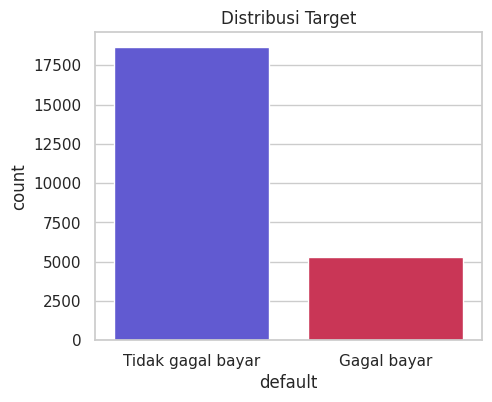

In [5]:
vc = df[TARGET].value_counts()
print(vc.to_dict(), '| proporsi gagal bayar =', round(df[TARGET].mean(), 4))
plt.figure(figsize=(5,4))
ax = sns.countplot(x=TARGET, data=df, palette=['#4f46e5','#e11d48'], hue=TARGET, legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(['Tidak gagal bayar','Gagal bayar'])
plt.title('Distribusi Target'); plt.show()

Hanya sekitar 22% nasabah yang gagal bayar, sehingga data **tidak seimbang**. Akurasi saja akan menyesatkan: model yang selalu menebak "tidak gagal bayar" sudah mencapai akurasi ~78%. Karena itu dipakai Precision, Recall, F1, dan AUC, serta SMOTE-NC pada data latih.

### 2.2 Hubungan Fitur dengan Target

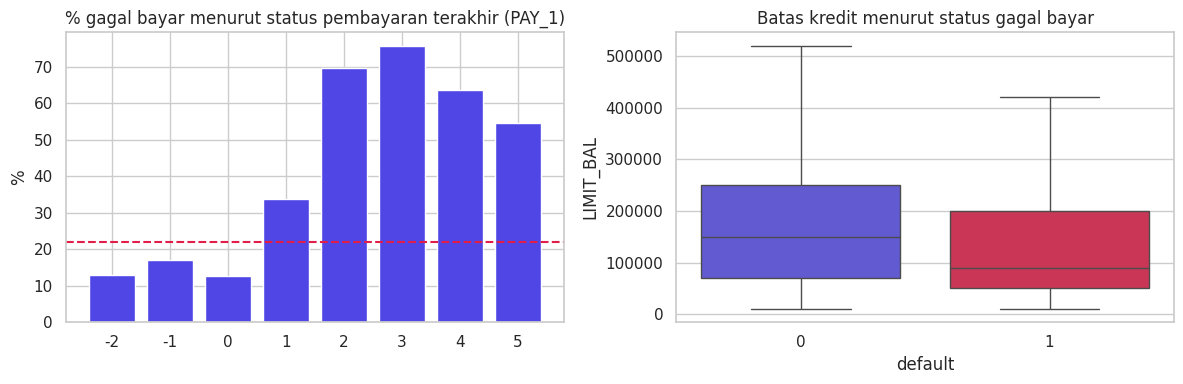

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
g = df.groupby('PAY_1')[TARGET].agg(['mean','size']); g = g[g['size']>=20]
ax[0].bar(g.index.astype(str), g['mean']*100, color='#4f46e5'); ax[0].axhline(df[TARGET].mean()*100, color='#e11d48', ls='--')
ax[0].set_title('% gagal bayar menurut status pembayaran terakhir (PAY_1)'); ax[0].set_ylabel('%')
sns.boxplot(data=df, x=TARGET, y='LIMIT_BAL', ax=ax[1], showfliers=False, palette=['#4f46e5','#e11d48'], hue=TARGET, legend=False)
ax[1].set_title('Batas kredit menurut status gagal bayar'); plt.tight_layout(); plt.show()

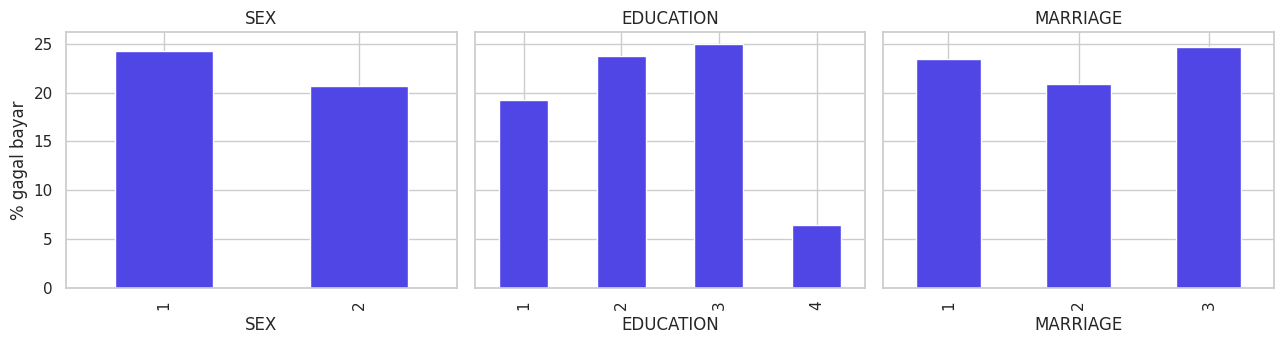

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, col in zip(ax, ['SEX','EDUCATION','MARRIAGE']):
    (df.groupby(col)[TARGET].mean()*100).plot.bar(ax=a, color='#4f46e5'); a.set_title(col); a.set_ylabel('% gagal bayar')
plt.tight_layout(); plt.show()

In [8]:
X_all = build_features(df)
corr = pd.concat([X_all, df[TARGET]], axis=1).corr()[TARGET].drop(TARGET).sort_values(ascending=False)
corr.head(8).round(3)

PAY_1          0.394
PAY_2          0.321
PAY_3          0.283
PAY_4          0.268
PAY_5          0.263
PAY_6          0.246
EDU_Sarjana    0.037
EDU_SMA        0.030
Name: default, dtype: float64

**Temuan:** keterlambatan pembayaran terbaru (`PAY_1`) adalah sinyal terkuat. Nasabah dengan tunggakan memiliki tingkat gagal bayar jauh di atas rata-rata.

## 3. Pra-pemrosesan untuk Model
- Variabel kategorikal (`SEX`, `EDUCATION`, `MARRIAGE`) diubah menjadi dummy.
- Kode `PAY_x` (-2/-1/0 = tidak ada tunggakan) diubah menjadi **bulan tunggakan** (0..9) agar hubungan dengan risiko monoton.
- Data dibagi 80:20 secara **stratified**, `StandardScaler` di-*fit* hanya pada data latih, lalu **SMOTE-NC** hanya pada data latih (SMOTE-NC menjaga kolom dummy tetap 0/1).

In [9]:
X = X_all; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
Xtr, Xte = X_train.copy(), X_test.copy()
Xtr[NUMERIC] = scaler.fit_transform(X_train[NUMERIC])
Xte[NUMERIC] = scaler.transform(X_test[NUMERIC])
print('Latih:', Xtr.shape, y_train.value_counts().to_dict(), '| Uji:', Xte.shape, y_test.value_counts().to_dict())
sm = SMOTENC(categorical_features=[Xtr.columns.get_loc(c) for c in DUMMY], random_state=42)
Xtr_sm, ytr_sm = sm.fit_resample(Xtr, y_train)
print('Setelah SMOTE-NC:', ytr_sm.value_counts().to_dict())

Latih: (19180, 26) {0: 14939, 1: 4241} | Uji: (4796, 26) {0: 3736, 1: 1060}


Setelah SMOTE-NC: {0: 14939, 1: 14939}


## 4. Pelatihan Model Regresi Logistik
Model baseline (tanpa penyeimbangan) dan `class_weight='balanced'` dilatih sebagai pembanding terhadap model final dengan SMOTE-NC.

In [10]:
base  = LogisticRegression(max_iter=2000, random_state=42).fit(Xtr, y_train)
cw    = LogisticRegression(max_iter=2000, random_state=42, class_weight='balanced').fit(Xtr, y_train)
model = LogisticRegression(max_iter=2000, random_state=42).fit(Xtr_sm, ytr_sm)
def ev(m, name, thr=0.5):
    p = m.predict_proba(Xte)[:,1]; pr = (p>=thr).astype(int)
    return dict(model=name, precision=precision_score(y_test, pr), recall=recall_score(y_test, pr), f1=f1_score(y_test, pr), auc=roc_auc_score(y_test, p))
pd.DataFrame([ev(base,'Tanpa penyeimbangan'), ev(cw,"class_weight='balanced'"), ev(model,'SMOTE-NC (final)')]).round(4)

,model,precision,recall,f1,auc
0,Tanpa penyeimbangan,0.6972,0.3519,0.4677,0.7600
1,class_weight='balanced',0.5086,0.5575,0.5320,0.7620
2,SMOTE-NC (final),0.5013,0.5632,0.5304,0.7571


## 5. Evaluasi Model Final
### 5.1 Confusion Matrix dan Classification Report

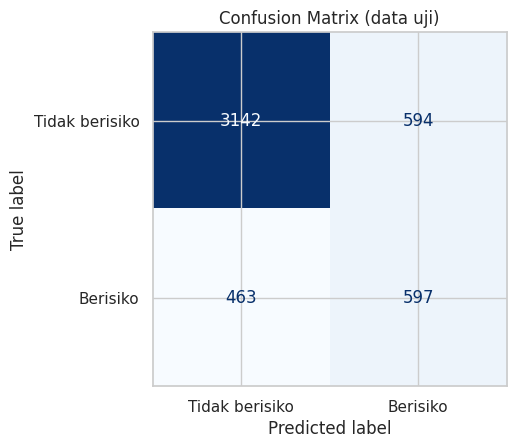

TN=3142  FP=594  FN=463  TP=597
                   precision    recall  f1-score   support

Tidak gagal bayar       0.87      0.84      0.86      3736
      Gagal bayar       0.50      0.56      0.53      1060

         accuracy                           0.78      4796
        macro avg       0.69      0.70      0.69      4796
     weighted avg       0.79      0.78      0.78      4796



In [11]:
proba = model.predict_proba(Xte)[:,1]
pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5.5,4.6))
ConfusionMatrixDisplay(cm, display_labels=['Tidak berisiko','Berisiko']).plot(cmap='Blues', ax=ax, colorbar=False)
plt.title('Confusion Matrix (data uji)'); plt.show()
tn, fp, fn, tp = cm.ravel(); print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(classification_report(y_test, pred, target_names=['Tidak gagal bayar','Gagal bayar']))

**Analisis kesalahan.** *False Positive* = nasabah baik yang diprediksi berisiko (ditinjau ulang atau limit ditahan, kehilangan sebagian pendapatan bunga). *False Negative* = nasabah yang akan gagal bayar tetapi dinilai aman (kredit macet, kerugian pokok). Bagi manajemen risiko, **False Negative lebih merugikan**, sehingga **Recall kelas "Gagal Bayar"** adalah metrik yang paling diperhatikan, dengan Precision dan F1 sebagai penyeimbang.

### 5.2 Kurva ROC dan AUC

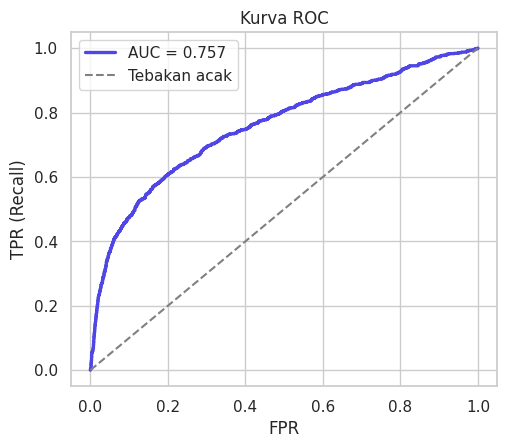

In [12]:
fpr, tpr, thr = roc_curve(y_test, proba); auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(5.5,4.6)); plt.plot(fpr, tpr, color='#4f46e5', lw=2.4, label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1],'--',color='gray',label='Tebakan acak'); plt.xlabel('FPR'); plt.ylabel('TPR (Recall)')
plt.title('Kurva ROC'); plt.legend(); plt.show()

### 5.3 Trade-off Ambang Batas (Threshold)

In [13]:
rows=[]
for t in np.arange(0.2, 0.81, 0.1):
    pr=(proba>=t).astype(int)
    rows.append(dict(threshold=round(t,2), precision=precision_score(y_test,pr), recall=recall_score(y_test,pr), f1=f1_score(y_test,pr),
                     FP=int(((pr==1)&(y_test==0)).sum()), FN=int(((pr==0)&(y_test==1)).sum())))
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,FP,FN
0,0.2,0.234,0.977,0.378,3392,24
1,0.3,0.254,0.909,0.397,2830,96
2,0.4,0.352,0.745,0.478,1454,270
3,0.5,0.501,0.563,0.530,594,463
4,0.6,0.561,0.485,0.520,403,546
5,0.7,0.651,0.408,0.501,232,628
6,0.8,0.696,0.325,0.443,150,716


Menurunkan threshold menaikkan Recall (lebih sedikit False Negative) dengan harga Precision yang turun (lebih banyak False Positive). Threshold akhir ditetapkan 0,5 sesuai ketentuan modul; lembaga keuangan dapat menurunkannya sesuai selera risiko.

### 5.4 Interpretasi Koefisien

In [14]:
coef = pd.DataFrame({'fitur': FEATURES, 'koefisien': model.coef_[0]})
coef['odds_ratio'] = np.exp(coef['koefisien'])
coef.reindex(coef['koefisien'].abs().sort_values(ascending=False).index).head(10).round(3)

,fitur,koefisien,odds_ratio
23,EDU_Lainnya,-2.412,0.090
25,MARRIAGE_Lainnya,-1.280,0.278
2,PAY_1,0.706,2.025
15,PAY_AMT2,-0.337,0.714
0,LIMIT_BAL,-0.257,0.774
22,EDU_SMA,-0.243,0.784
24,MARRIAGE_Lajang,-0.226,0.798
8,BILL_AMT1,-0.179,0.836
14,PAY_AMT1,-0.178,0.837
10,BILL_AMT3,0.162,1.176


Untuk fitur numerik terstandarisasi, odds ratio menyatakan perubahan odds gagal bayar untuk kenaikan 1 simpangan baku. Tunggakan bulan terbaru (`PAY_1`) memiliki pengaruh positif terbesar di antara fitur numerik. Catatan: koefisien kategori langka (misalnya pendidikan "lainnya") kurang stabil karena sampelnya sedikit.

## 6. Penyimpanan Model
Model dan objek scaler disimpan dengan Joblib (file final dihasilkan oleh `train.py`).

In [15]:
import os, tempfile
tmp = tempfile.mkdtemp()
joblib.dump(model, os.path.join(tmp,'model_logreg.joblib')); joblib.dump(scaler, os.path.join(tmp,'scaler.joblib'))
print(os.listdir(tmp))

['model_logreg.joblib', 'scaler.joblib']


## 7. Kesimpulan Bisnis
1. Riwayat tunggakan adalah indikator terkuat gagal bayar; pemantauan dini nasabah yang mulai menunggak paling efektif menekan kerugian.
2. Model mendeteksi sekitar 56% nasabah yang akan gagal bayar dengan Precision sekitar 50% dan AUC sekitar 0,76.
3. Karena False Negative lebih mahal, ambang keputusan dapat diturunkan untuk menaikkan Recall, dengan konsekuensi beban peninjauan manual yang lebih besar.
4. Model adalah alat bantu keputusan. Keputusan kredit akhir tetap perlu mempertimbangkan faktor lain dan kebijakan perusahaan.